# CARS Spectroscopy Temperature Inversion


<!-- inverse-evidence-audit:20261026:start -->

> **本次维护说明：** 以下导航依据当前观测文件、实际求解代码和保留的输出编写。本次仅完善叙述，不把历史图、缓存结果或未执行代码称作本次新计算；没有独立 GT 时，方法参考不代表真实准确性。

### 观测 → 物理目标：cars_spectroscopy

**观测 y：** Notebook数据加载单元所列旧路径（标准data/raw_data.npz不存在，需迁移前核实）。具体单位以本Notebook数据表及README为准。

**恢复目标 x：** 气体温度/摩尔分数及谱形参数。

**GT/参考来源：** GT为生成观测之前定义的模拟物理目标；须与无噪声观测/拟合预测区分。

**由观测恢复目标：** G矩阵共振极化率与非共振背景干涉后仪器卷积。本地路径为 `solvers.run_inversion→scipy.least_squares`。现有Notebook仅展示缓存结果，尚未主动执行完整观测到目标路径，历史图不能标成此次新求解。

**现有实验与图：** 保留图像输出位于cell 4, 6, 8（cell编号按文件内从0计）。章节包括：# CARS Spectroscopy Temperature Inversion；### Visualize Ground Truth vs Measurement；### Inversion Result；### Residuals；### Metrics；### Run Full Pipeline from Scratch (Optional)；## 6. Conclusion。应联合阅读观测图、完整恢复目标、参考差异与残差/敏感性实验；方法一致性不等于物理精度。

**限制：** Notebook仅加载缓存，完整反演被注释；标准文件缺失/旧布局。

**当前资产限制：** 本工作树缺少绑定raw；保留图和执行计数不证明现在可以运行，目标来源仍需资产核验。

<!-- inverse-evidence-audit:20261026:end -->


## 1. Problem


This notebook demonstrates the end-to-end pipeline for recovering gas temperature from a synthetic N2 coherent anti-Stokes Raman scattering (CARS) spectrum.

**Pipeline stages:**
1. Load precomputed data and reference outputs
2. Visualize the ground truth and noisy measurement
3. Show the inversion result (precomputed)
4. Evaluate metrics

The results are loaded from `evaluation/reference_outputs/` so this notebook runs in seconds.

## 2. Data

### Load Data



### data/raw_data.npz

| Key | Shape | Dtype | Description |
|-----|-------|-------|-------------|
| `measurements` | `(1, 200)` | float64 | Noisy normalized CARS intensity spectrum (dimensionless) |
| `nu_axis` | `(1, 200)` | float64 | Wavenumber axis ($cm^{-1}$) |

## 3. Physics

At wavenumber $\nu$ (cm$^{-1}$), gas temperature $T$ (K), pressure $P$ and nitrogen mole fraction $x$, the coherent susceptibility combines resonant and nonresonant contributions:

$$
I(\nu)=|xN\chi_{\mathrm{RS}}(\nu;T,P)+\chi_{\mathrm{NR}}(x,P,T)|^2*S_{\mathrm{pump}}*S_{\mathrm{slit}}.
$$

$N$ is number density, the two $S$ terms represent pump and slit broadening, and $*$ denotes convolution. The resonant G-matrix is $K=\operatorname{diag}(\nu_{\mathrm{Raman}})+\mathrm{i}\Gamma$, with line positions $\nu_{\mathrm{Raman}}$ and collisional relaxation matrix $\Gamma$. Off-diagonal rotational energy transfer matters for overlapping high-pressure lines; an isolated-line fit changes the physical model.

## 4. Method

Local code constructs the Q/O/S transitions, relaxation matrix, susceptibility and broadening, then uses trust-region reflective nonlinear least squares. Free parameters are temperature, mole fraction, spectral shift and slit width; spectral stretch is fixed. This notebook loads the saved fit rather than calling that optimizer: the final reproduction cell is commented out.

## 5. Results

The plotted fit and temperature are saved measurements. The retained residual and metric cells compare that fit with noisy observations and the simulated truth; they do not constitute a fresh inversion. Spectral agreement and temperature error answer different questions because nuisance broadening can compensate temperature changes.


In [1]:
import sys, os
sys.path.insert(0, os.path.join(os.getcwd(), '..'))
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

In [2]:
data_dir = os.path.join('..', 'data')
ref_dir = os.path.join('..', 'evaluation', 'reference_outputs')

raw = np.load(os.path.join(data_dir, 'raw_data.npz'))
gt = np.load(os.path.join(data_dir, 'ground_truth.npz'))
recon = np.load(os.path.join(ref_dir, 'reconstruction.npz'))

measurements = raw['measurements'][0]
nu_axis = raw['nu_axis'][0]
gt_spectrum = gt['spectrum'][0]
gt_temperature = float(gt['temperature'][0])

y_pred = recon['y_pred'][0]
T_pred = float(recon['temperature_pred'][0])

print(f"Wavenumber range: {nu_axis[0]:.1f} - {nu_axis[-1]:.1f} cm-1 ({len(nu_axis)} points)")
print(f"Ground truth temperature: {gt_temperature:.0f} K")
print(f"Predicted temperature: {T_pred:.1f} K")

Wavenumber range: 2280.0 - 2330.0 cm-1 (200 points)
Ground truth temperature: 2400 K
Predicted temperature: 2391.6 K


### Visualize Ground Truth vs Measurement


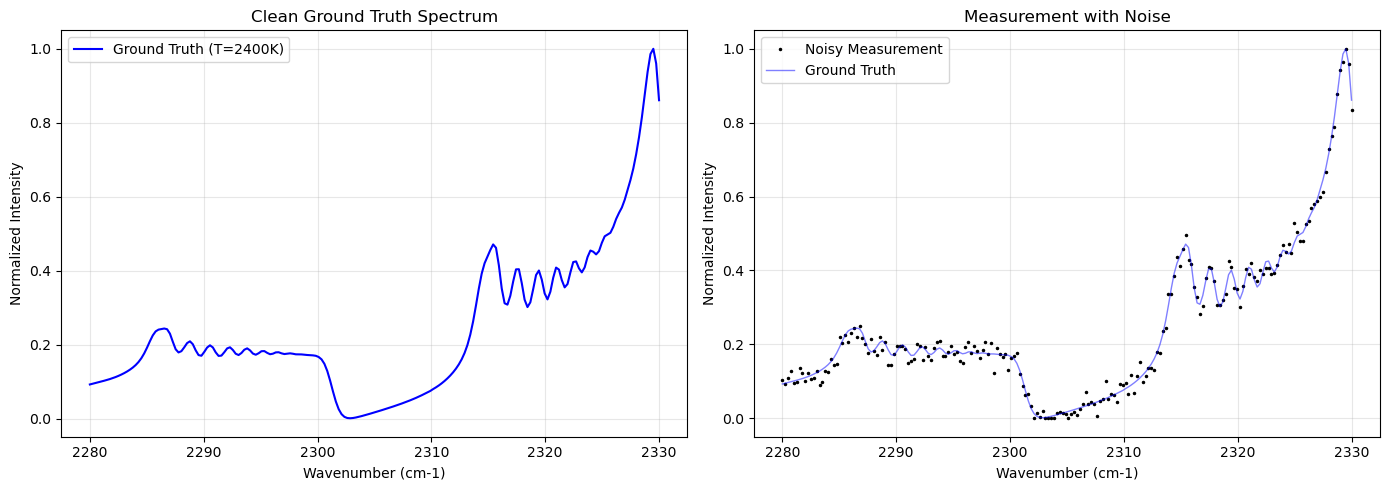

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(nu_axis, gt_spectrum, 'b-', linewidth=1.5, label=f'Ground Truth (T={gt_temperature:.0f}K)')
axes[0].set_xlabel('Wavenumber (cm-1)')
axes[0].set_ylabel('Normalized Intensity')
axes[0].set_title('Clean Ground Truth Spectrum')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].plot(nu_axis, measurements, 'k.', markersize=3, label='Noisy Measurement')
axes[1].plot(nu_axis, gt_spectrum, 'b-', alpha=0.5, linewidth=1, label='Ground Truth')
axes[1].set_xlabel('Wavenumber (cm-1)')
axes[1].set_ylabel('Normalized Intensity')
axes[1].set_title('Measurement with Noise')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### Inversion Result


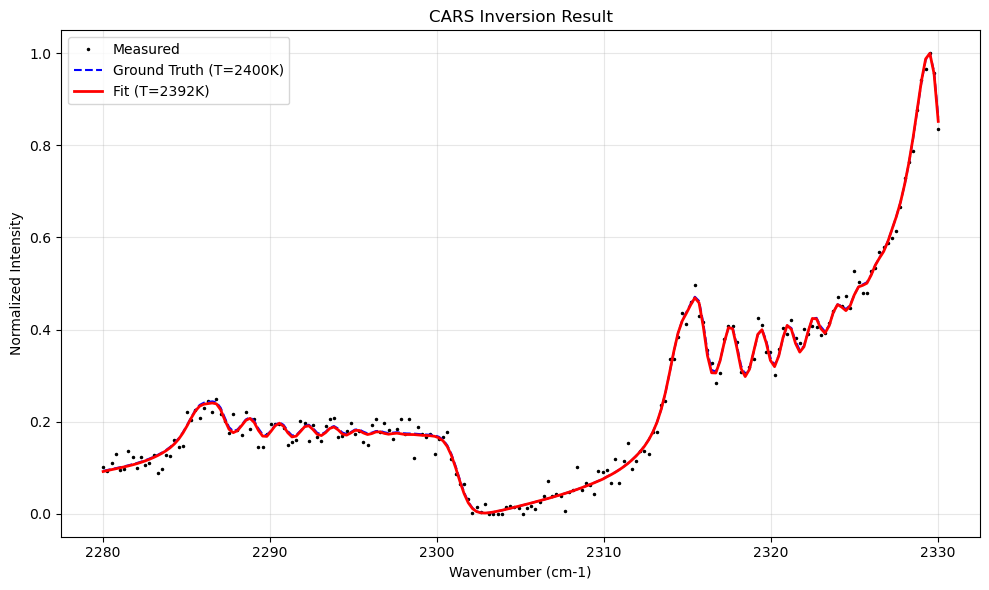

In [4]:
plt.figure(figsize=(10, 6))
plt.plot(nu_axis, measurements, 'k.', markersize=3, label='Measured')
plt.plot(nu_axis, gt_spectrum, 'b--', linewidth=1.5, label=f'Ground Truth (T={gt_temperature:.0f}K)')
plt.plot(nu_axis, y_pred, 'r-', linewidth=2, label=f'Fit (T={T_pred:.0f}K)')
plt.xlabel('Wavenumber (cm-1)')
plt.ylabel('Normalized Intensity')
plt.title('CARS Inversion Result')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### Residuals


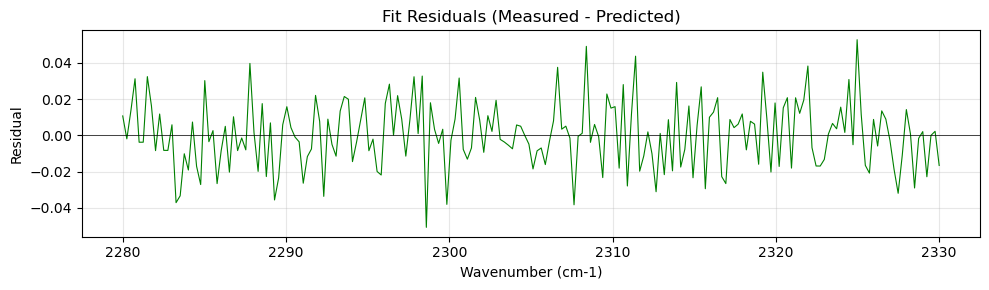

In [5]:
residual = measurements - y_pred

plt.figure(figsize=(10, 3))
plt.plot(nu_axis, residual, 'g-', linewidth=0.8)
plt.axhline(0, color='k', linewidth=0.5)
plt.xlabel('Wavenumber (cm-1)')
plt.ylabel('Residual')
plt.title('Fit Residuals (Measured - Predicted)')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### Metrics


In [6]:
from src.visualization import compute_metrics

metrics = compute_metrics(measurements, y_pred,
                          {'temperature': T_pred},
                          params_true={'temperature': gt_temperature})

print("=" * 45)
print("  CARS Inversion Metrics")
print("=" * 45)
for k, v in metrics.items():
    if isinstance(v, float):
        print(f"  {k:25s}: {v:.6f}")
    else:
        print(f"  {k:25s}: {v}")
print("=" * 45)

  CARS Inversion Metrics
  mse                      : 0.000333
  psnr_dB                  : 34.779548
  ncc                      : 0.998361
  nrmse                    : 0.018240
  temperature_error_K      : 8.435821
  temperature_true_K       : 2400.000000
  temperature_pred_K       : 2391.564179


### Run Full Pipeline from Scratch (Optional)

Uncomment and run the cell below to execute the full inversion pipeline instead of loading precomputed results. This takes about 10-20 seconds.


In [7]:
# from src.preprocessing import load_and_preprocess_data
# from src.solvers import run_inversion
# from src.visualization import plot_inversion_result
#
# processed_signal, nu_proc = load_and_preprocess_data(measurements, nu_axis, noise_level=0.0)
#
# initial_guesses = {
#     'temperature': 2000,
#     'x_mol': 0.79,
#     'pressure': 1.0,
#     'pump_lw': 1.0,
# }
#
# result = run_inversion(processed_signal, nu_proc, initial_guesses)
# print(f"Fitted temperature: {result['best_params']['temperature']:.1f} K")
# print(f"Success: {result['success']}, Cost: {result['cost']:.6e}")

## 6. Conclusion

The saved comparison illustrates recovery of a synthetic gas temperature under the selected G-matrix model. Interpret only the actual displayed metrics; the notebook does not actively rerun the inverse problem. A fresh reconstruction and verified execution remain separate gates, and performance on real flame spectra is not established by this synthetic case.
